## 0. Imports and reproducibility

In [1]:
import os, re, time, random, math
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.makedirs("outputs", exist_ok=True)


## 1. Core implementation — stable softmax and scaled dot-product attention

In [2]:
def softmax_stable(x, axis=-1):
    x = np.asarray(x, dtype=np.float64)
    shifted = x - np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(shifted)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)

def scaled_dot_product_attention(Q, K, V):
    Q, K, V = map(lambda a: np.asarray(a, dtype=np.float64), (Q, K, V))
    if Q.ndim != 2 or K.ndim != 2 or V.ndim != 2:
        raise ValueError("Q, K, V phải là ma trận 2 chiều.")
    if Q.shape[1] != K.shape[1]:
        raise ValueError("Q và K phải có cùng số chiều đặc trưng.")
    if K.shape[0] != V.shape[0]:
        raise ValueError("K và V phải có cùng số token.")
    d_k = K.shape[1]
    scores = (Q @ K.T) / np.sqrt(d_k)
    attention_weights = softmax_stable(scores, axis=-1)
    context = attention_weights @ V
    return scores, attention_weights, context

def self_attention(X, W_Q, W_K, W_V):
    Q = np.asarray(X) @ np.asarray(W_Q)
    K = np.asarray(X) @ np.asarray(W_K)
    V = np.asarray(X) @ np.asarray(W_V)
    scores, weights, context = scaled_dot_product_attention(Q, K, V)
    return Q, K, V, scores, weights, context


## 2. Unit checks and numerical stability

In [3]:
test_softmax = softmax_stable(np.array([1000., 1001., 1002.]))
print("softmax([1000, 1001, 1002]) =", test_softmax)
assert np.isfinite(test_softmax).all()
assert np.isclose(test_softmax.sum(), 1.0)

q = np.array([[1., 0.]])
K_demo = np.array([[1., 0.], [0., 1.], [1., 1.]])
V_demo = np.array([[1., 0.], [0., 2.], [2., 1.]])
scores_demo, weights_demo, context_demo = scaled_dot_product_attention(q, K_demo, V_demo)
print("scores =", scores_demo)
print("weights =", weights_demo)
print("context =", context_demo)
assert np.allclose(weights_demo.sum(axis=-1), 1.0)


softmax([1000, 1001, 1002]) = [0.09003057 0.24472847 0.66524096]
scores = [[0.70710678 0.         0.70710678]]
weights = [[0.40111209 0.19777581 0.40111209]]
context = [[1.20333628 0.79666372]]


## 3. Experiment 1 — distribution and query changes

,token,sentiment_score,sentiment_attention,topic_score,topic_attention
0,The,-0.510742,0.044175,-1.498681,0.018849
1,movie,0.726568,0.152241,-1.243591,0.024326
2,was,0.382014,0.107868,-1.030270,0.030110
3,surprisingly,0.398263,0.109635,-0.443616,0.054137
4,good,0.930820,0.186739,-0.214289,0.068091
5,despite,0.767903,0.158665,0.548141,0.145952
6,a,-0.426278,0.048068,-0.631273,0.044874
7,very,-1.266371,0.020750,1.616492,0.424806
8,slow,0.609772,0.135459,-0.187483,0.069941
9,beginning,-0.704291,0.036401,0.343243,0.118912


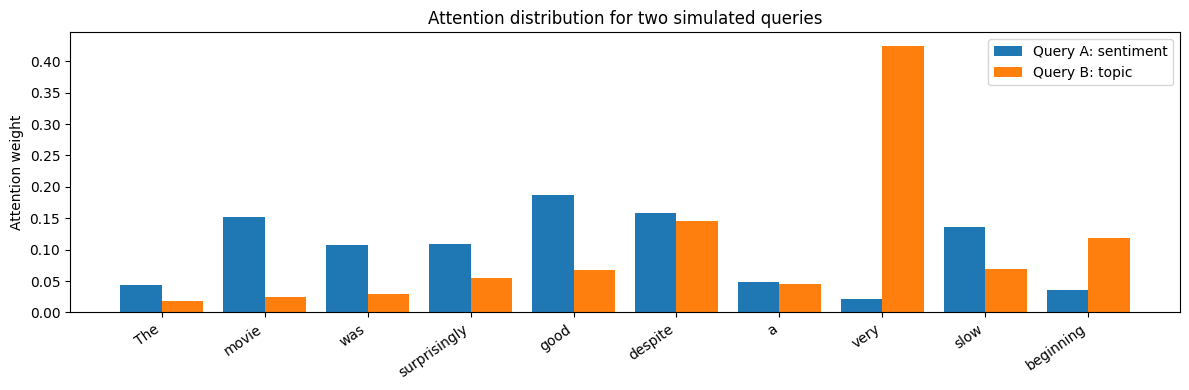

In [4]:
tokens = ["The", "movie", "was", "surprisingly", "good", "despite", "a", "very", "slow", "beginning"]
# Simulated token representations/query for the lab's controlled experiment.
rng = np.random.default_rng(SEED)
token_vectors = rng.normal(size=(len(tokens), 8))
query_sentiment = np.array([0.8, -0.2, 0.1, 0.9, 1.0, -0.1, 0.0, 0.2])
query_topic = np.array([-0.1, 1.0, 0.2, 0.0, 0.1, 0.1, 0.0, 0.8])
# Project the 8-d token vectors to 8-d query-compatible vectors.
scores_sentiment = token_vectors @ query_sentiment
scores_topic = token_vectors @ query_topic
weights_sentiment = softmax_stable(scores_sentiment)
weights_topic = softmax_stable(scores_topic)
distribution_df = pd.DataFrame({
    "token": tokens,
    "sentiment_score": scores_sentiment,
    "sentiment_attention": weights_sentiment,
    "topic_score": scores_topic,
    "topic_attention": weights_topic
})
display(distribution_df)
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(tokens))
ax.bar(x - 0.2, weights_sentiment, width=0.4, label="Query A: sentiment")
ax.bar(x + 0.2, weights_topic, width=0.4, label="Query B: topic")
ax.set_xticks(x); ax.set_xticklabels(tokens, rotation=35, ha="right")
ax.set_ylabel("Attention weight"); ax.legend(); ax.set_title("Attention distribution for two simulated queries")
plt.tight_layout()
plt.savefig("outputs/attention_distribution.png", dpi=160, bbox_inches="tight")
plt.show()


## 4. Experiment 2 — scaling and temperature

In [5]:
raw_scores = np.array([4., 2., 0.])
scaled_scores = raw_scores / np.sqrt(4)
scenarios = []
for name, scores in [("dot product", raw_scores), ("scaled dot product (d_k=4)", scaled_scores)]:
    p = softmax_stable(scores)
    entropy = -np.sum(p * np.log(p + 1e-12))
    scenarios.append({"experiment": name, "max_weight": float(p.max()), "entropy": float(entropy), "weights": p.tolist()})
for temperature in [0.5, 1.0, 2.0]:
    p = softmax_stable(raw_scores / temperature)
    entropy = -np.sum(p * np.log(p + 1e-12))
    scenarios.append({"experiment": f"temperature={temperature}", "max_weight": float(p.max()), "entropy": float(entropy), "weights": p.tolist()})
temperature_df = pd.DataFrame(scenarios)
display(temperature_df)
temperature_df.to_csv("outputs/temperature_experiment.csv", index=False)


,experiment,max_weight,entropy,weights
0,dot product,0.866813,0.441057,"[0.8668133321973347, 0.11731042782619835, 0.01..."
1,scaled dot product (d_k=4),0.665241,0.832396,"[0.6652409557748218, 0.24472847105479764, 0.09..."
2,temperature=0.5,0.981690,0.093035,"[0.9816903928255046, 0.017980286735531543, 0.0..."
3,temperature=1.0,0.866813,0.441057,"[0.8668133321973347, 0.11731042782619835, 0.01..."
4,temperature=2.0,0.665241,0.832396,"[0.6652409557748218, 0.24472847105479764, 0.09..."


## 5. Experiment 3 — Self-attention matrix and heatmap

Shapes: Q (8, 8) K (8, 8) V (8, 8) attention (8, 8) context (8, 8)


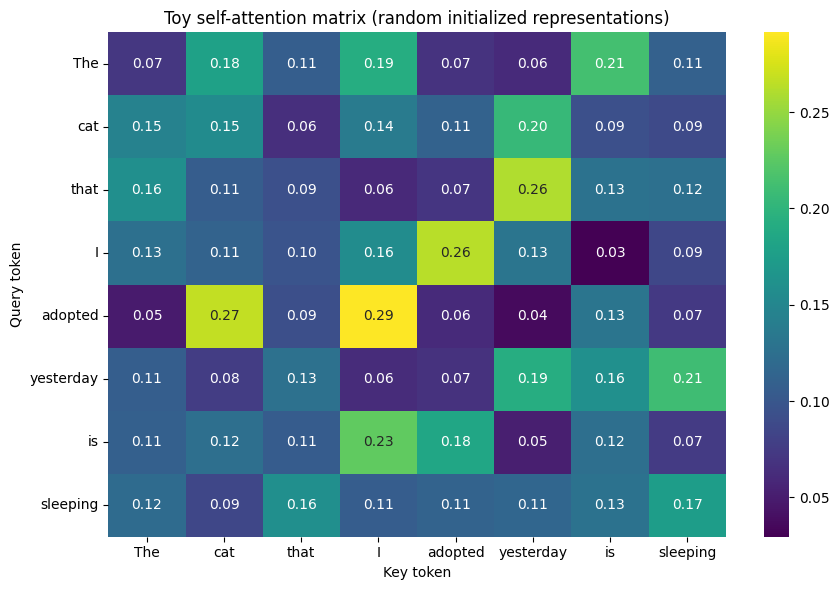

In [6]:
sentence = ["The", "cat", "that", "I", "adopted", "yesterday", "is", "sleeping"]
# Toy embeddings are used to demonstrate matrix shapes and plotting.
rng = np.random.default_rng(SEED + 1)
X_toy = rng.normal(size=(len(sentence), 8))
W_Q = rng.normal(scale=0.3, size=(8, 8))
W_K = rng.normal(scale=0.3, size=(8, 8))
W_V = rng.normal(scale=0.3, size=(8, 8))
Q, K, V, scores, attn, context = self_attention(X_toy, W_Q, W_K, W_V)
print("Shapes:", "Q", Q.shape, "K", K.shape, "V", V.shape, "attention", attn.shape, "context", context.shape)
assert attn.shape == (len(sentence), len(sentence))
plt.figure(figsize=(9, 6))
sns.heatmap(attn, xticklabels=sentence, yticklabels=sentence, cmap="viridis", annot=True, fmt=".2f")
plt.title("Toy self-attention matrix (random initialized representations)")
plt.xlabel("Key token"); plt.ylabel("Query token")
plt.tight_layout()
plt.savefig("outputs/attention_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()


### Individual interpretation — complete yourself
Inspect the heatmap generated above. Describe only the visible attention pattern first, then write your own hypothesis about possible linguistic relationships. Do not claim the heatmap proves reasoning or grammatical understanding.


## 6. Experiment 4 — sequence-length cost

In [7]:
lengths = [10, 100, 500, 1000]
length_df = pd.DataFrame({"sequence_length_T": lengths, "attention_matrix_shape": [f"{t} x {t}" for t in lengths],
                          "number_of_scores_T_squared": [t*t for t in lengths]})
display(length_df)
length_df.to_csv("outputs/sequence_length_cost.csv", index=False)


,sequence_length_T,attention_matrix_shape,number_of_scores_T_squared
0,10,10 x 10,100
1,100,100 x 100,10000
2,500,500 x 500,250000
3,1000,1000 x 1000,1000000


## 7. Application — context-aware sentiment classifier
The following cell uses a small PyTorch model with embedding → self-attention → masked mean pooling → classifier. It tries to load the IMDB dataset using `datasets`; if unavailable, install `datasets` first. For practical runtime, it samples a subset. Change `N_TRAIN`/`N_TEST` and epochs only if runtime allows.


In [8]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)


Device: cpu


In [9]:
# Data loading: IMDB reviews, binary labels (0=negative, 1=positive).
try:
    from datasets import load_dataset
    imdb = load_dataset("stanfordnlp/imdb")
    raw_train = pd.DataFrame({"text": imdb["train"]["text"], "label": imdb["train"]["label"]})
    raw_test = pd.DataFrame({"text": imdb["test"]["text"], "label": imdb["test"]["label"]})
except Exception as e:
    raise RuntimeError("Không tải được IMDB. Cài `datasets` và kiểm tra Internet, rồi chạy lại cell này.") from e

N_TRAIN, N_TEST = 4000, 1000
raw_train = raw_train.sample(n=min(N_TRAIN, len(raw_train)), random_state=SEED).reset_index(drop=True)
raw_test = raw_test.sample(n=min(N_TEST, len(raw_test)), random_state=SEED).reset_index(drop=True)
train_df, val_df = train_test_split(raw_train, test_size=0.2, random_state=SEED, stratify=raw_train["label"])


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [10]:
def tokenize(text):
    return re.findall(r"\b\w+\b|[^\w\s]", str(text).lower())

MAX_VOCAB = 15000
PAD_ID, UNK_ID = 0, 1
counter = Counter(tok for text in train_df["text"] for tok in tokenize(text))
vocab = {"<PAD>": PAD_ID, "<UNK>": UNK_ID}
vocab.update({w: i + 2 for i, (w, _) in enumerate(counter.most_common(MAX_VOCAB - 2))})
MAX_LEN = 160

def encode(text):
    ids = [vocab.get(tok, UNK_ID) for tok in tokenize(text)[:MAX_LEN]]
    ids += [PAD_ID] * (MAX_LEN - len(ids))
    return ids

class ReviewDataset(Dataset):
    def __init__(self, frame):
        self.texts = frame["text"].tolist()
        self.labels = frame["label"].astype(int).tolist()
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        ids = torch.tensor(encode(self.texts[i]), dtype=torch.long)
        return ids, torch.tensor(self.labels[i], dtype=torch.long)

train_loader = DataLoader(ReviewDataset(train_df), batch_size=64, shuffle=True)
val_loader = DataLoader(ReviewDataset(val_df), batch_size=128)
test_loader = DataLoader(ReviewDataset(raw_test), batch_size=128)


In [11]:
class SelfAttentionSentiment(nn.Module):
    def __init__(self, vocab_size, emb_dim=64, num_classes=2, pad_id=PAD_ID):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_id)
        self.q_proj = nn.Linear(emb_dim, emb_dim, bias=False)
        self.k_proj = nn.Linear(emb_dim, emb_dim, bias=False)
        self.v_proj = nn.Linear(emb_dim, emb_dim, bias=False)
        self.classifier = nn.Sequential(nn.Linear(emb_dim, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, num_classes))
        self.pad_id = pad_id
    def forward(self, ids, return_attention=False):
        mask = ids.ne(self.pad_id)
        X = self.embedding(ids)
        Q, K, V = self.q_proj(X), self.k_proj(X), self.v_proj(X)
        scores = Q @ K.transpose(1, 2) / math.sqrt(Q.shape[-1])
        # Mask padding keys before softmax for stable, meaningful weights.
        scores = scores.masked_fill(~mask.unsqueeze(1), -1e9)
        weights = torch.softmax(scores, dim=-1)
        context = weights @ V
        # Masked mean pooling makes one vector per review.
        context = context * mask.unsqueeze(-1)
        pooled = context.sum(dim=1) / mask.sum(dim=1, keepdim=True).clamp(min=1)
        logits = self.classifier(pooled)
        if return_attention:
            return logits, weights, mask
        return logits

model = SelfAttentionSentiment(len(vocab)).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)
criterion = nn.CrossEntropyLoss()


In [12]:
def run_epoch(model, loader, train=False):
    model.train(train)
    total_loss, all_y, all_pred = 0.0, [], []
    for ids, labels in loader:
        ids, labels = ids.to(DEVICE), labels.to(DEVICE)
        if train: optimizer.zero_grad()
        with torch.set_grad_enabled(train):
            logits = model(ids)
            loss = criterion(logits, labels)
            if train:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
        total_loss += loss.item() * len(labels)
        all_y.extend(labels.detach().cpu().numpy().tolist())
        all_pred.extend(logits.argmax(dim=1).detach().cpu().numpy().tolist())
    return total_loss / len(loader.dataset), accuracy_score(all_y, all_pred), f1_score(all_y, all_pred), np.array(all_y), np.array(all_pred)

history, start = [], time.time()
EPOCHS = 3
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc, train_f1, _, _ = run_epoch(model, train_loader, train=True)
    val_loss, val_acc, val_f1, _, _ = run_epoch(model, val_loader, train=False)
    row = {"epoch": epoch, "train_loss": train_loss, "train_accuracy": train_acc, "train_f1": train_f1,
           "val_loss": val_loss, "val_accuracy": val_acc, "val_f1": val_f1}
    history.append(row)
    print(row)
print("Training time (seconds):", round(time.time() - start, 2))


{'epoch': 1, 'train_loss': 0.6773315393924713, 'train_accuracy': 0.56875, 'train_f1': 0.5499021526418787, 'val_loss': 0.6388762164115905, 'val_accuracy': 0.63375, 'val_f1': 0.6581096849474912}
{'epoch': 2, 'train_loss': 0.5691708385944366, 'train_accuracy': 0.703125, 'train_f1': 0.7098350641417227, 'val_loss': 0.5974245405197144, 'val_accuracy': 0.68, 'val_f1': 0.6404494382022472}
{'epoch': 3, 'train_loss': 0.4546588397026062, 'train_accuracy': 0.794375, 'train_f1': 0.7863636363636364, 'val_loss': 0.5623497748374939, 'val_accuracy': 0.71, 'val_f1': 0.71}
Training time (seconds): 15.52


,model,train_samples,validation_samples,test_samples,accuracy,f1,test_loss,training_time_seconds,parameters
0,SelfAttentionSentiment,3200,800,1000,0.745,0.73953,0.516436,16.12,976578


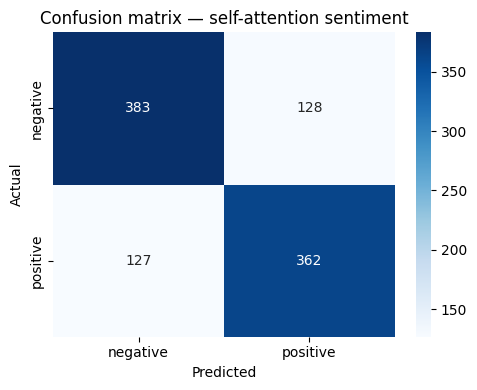

In [13]:
test_loss, test_acc, test_f1, y_true, y_pred = run_epoch(model, test_loader, train=False)
results = pd.DataFrame([{
    "model": "SelfAttentionSentiment",
    "train_samples": len(train_df), "validation_samples": len(val_df), "test_samples": len(raw_test),
    "accuracy": test_acc, "f1": test_f1, "test_loss": test_loss,
    "training_time_seconds": round(time.time() - start, 2), "parameters": sum(p.numel() for p in model.parameters())
}])
display(results)
results.to_csv("results.csv", index=False)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["negative", "positive"], yticklabels=["negative", "positive"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix — self-attention sentiment")
plt.tight_layout()
plt.savefig("outputs/confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()


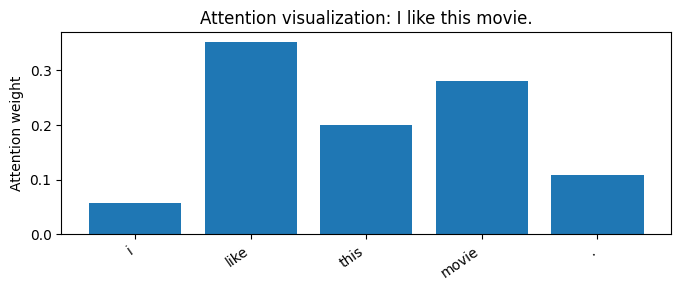

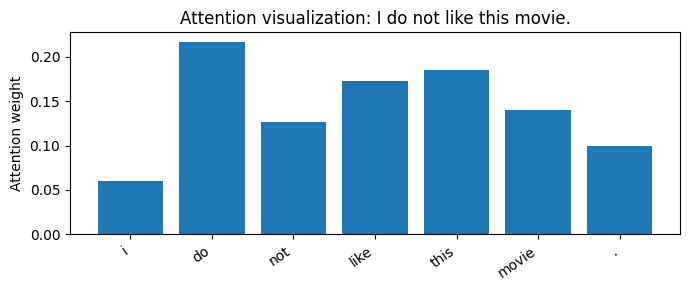

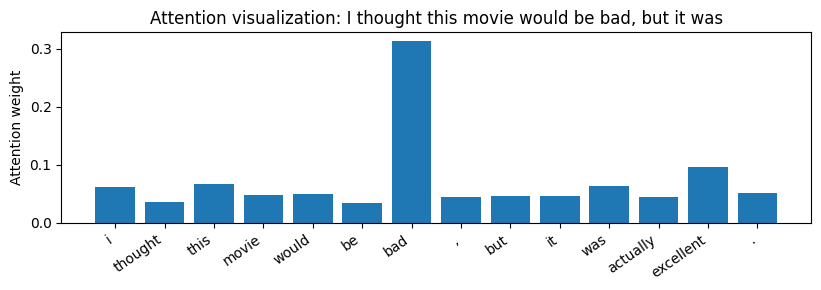

,text,prediction,probability_negative,probability_positive
0,I like this movie.,negative,0.949224,0.050776
1,I do not like this movie.,negative,0.966878,0.033122
2,"I thought this movie would be bad, but it was ...",negative,0.913683,0.086317


In [14]:
def predict_sentiment(text):
    model.eval()
    ids = torch.tensor([encode(text)], dtype=torch.long, device=DEVICE)
    with torch.no_grad():
        logits, weights, mask = model(ids, return_attention=True)
        probs = torch.softmax(logits, dim=-1)[0].cpu().numpy()
    tokens = tokenize(text)[:MAX_LEN]
    attn = weights[0, :len(tokens), :len(tokens)].mean(dim=0).cpu().numpy()
    return {"prediction": "positive" if probs[1] >= probs[0] else "negative",
            "probability_negative": float(probs[0]), "probability_positive": float(probs[1]),
            "tokens": tokens, "attention": attn}

examples = [
    "I like this movie.",
    "I do not like this movie.",
    "I thought this movie would be bad, but it was actually excellent."
]
example_rows = []
for sentence in examples:
    out = predict_sentiment(sentence)
    example_rows.append({"text": sentence, "prediction": out["prediction"],
                         "probability_negative": out["probability_negative"],
                         "probability_positive": out["probability_positive"]})
    plt.figure(figsize=(max(7, len(out["tokens"])*0.6), 3))
    plt.bar(out["tokens"], out["attention"])
    plt.xticks(rotation=35, ha="right"); plt.ylabel("Attention weight")
    plt.title("Attention visualization: " + sentence[:45])
    plt.tight_layout()
    safe_name = re.sub(r"[^a-z0-9]+", "_", sentence.lower()).strip("_")[:35]
    plt.savefig(f"outputs/attention_{safe_name}.png", dpi=160, bbox_inches="tight")
    plt.show()
example_predictions = pd.DataFrame(example_rows)
display(example_predictions)
example_predictions.to_csv("outputs/example_predictions.csv", index=False)


## 8. Error-analysis workspace — do not auto-generate conclusions
Review the model's actual predictions. Choose 3 correct and 3 incorrect examples from `raw_test`, record them and classify each error (negation, long-range dependency, ambiguous wording, sarcasm, rare word, domain shift, truncation, noise). Use your own interpretation of the attention plots.


In [15]:
# Candidate table to inspect after the model has run.
error_review = pd.DataFrame({"text": raw_test["text"], "actual": raw_test["label"], "predicted": y_pred})
error_review["correct"] = error_review["actual"].to_numpy() == error_review["predicted"].to_numpy()
display(error_review.loc[~error_review["correct"]].head(10))


,text,actual,predicted,correct
1,I rented Boogie Nights last week and I could t...,1,0,False
7,I just watched it for the second time today an...,1,0,False
12,"Some folkie friends recommended this, but as a...",0,1,False
15,The movie was very good. I'm an avid mystery f...,1,0,False
17,OK. So it can be done! We have here the perfec...,1,0,False
19,Hadn't really heard too much about this movie ...,0,1,False
23,I deliberately did not read any reviews of thi...,0,1,False
24,Waters's contribution to the world of cinema h...,0,1,False
25,"Uzumaki, is a visually stunning Film, and I do...",1,0,False
31,is not a bad movie but the acting and the scre...,1,0,False


## 9. Export generated artifacts
After the notebook finishes, copy `outputs/attention_heatmap.png` and `outputs/confusion_matrix.png` into the root of `lab06/` if your submission requires the exact names listed in W6. Check all outputs before submitting.


In [16]:
# Copy the required images to the lab06 root for the submission structure.
import shutil
for src, dst in [
    ("outputs/attention_heatmap.png", "attention_heatmap.png"),
    ("outputs/confusion_matrix.png", "confusion_matrix.png"),
]:
    if os.path.exists(src):
        shutil.copy2(src, dst)
print("Export step complete.")


Export step complete.
